# Exploratory Data Analysis

**Purpose:** Explore booking trends, service demand, staff performance, revenue, and retention.


## 1. Load and Validate

In [18]:
# Import necessary libraries
import sys
sys.path.append("..")
 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from src.validate import validate

sns.set_theme(style="whitegrid")   
FIG = Path(".../reports/figures"); 
FIG.mkdir(parents=True, exist_ok=True)

In [19]:
# Load and revalidate data
df = pd.read_parquet("../data/processed/booking_clean.parquet")
df = validate(df)

All checks passed: 49,462 rows, 20 columns


In [23]:
# Overview
print("Rows:", f"{len(df)}", "Columns:", f"{df.shape[1]}")
print("Date range:", df["start"].min().date(), "to", df["start"].max().date())
print("Unique customers:", df["id"].nunique())
print("Number of appointments:", df["number"].nunique()) 
print()
print(df["status"].value_counts(normalize=True).round(3))
print(df["source"].value_counts(normalize=True).round(3))
print(df["service_type"].value_counts(normalize=True).round(3))

Rows: 49462 Columns: 20
Date range: 2024-08-09 to 2026-10-31
Unique customers: 5219
Number of appointments: 38926

status
Completed    0.900
Cancel       0.092
No-show      0.007
Name: proportion, dtype: float64
source
2025.csv    0.439
2026.csv    0.426
2024.csv    0.135
Name: proportion, dtype: float64
service_type
Natural Nails        0.439
Nails Enhancement    0.437
Add-ons              0.049
Bare Necessities     0.039
Waxing Services      0.025
Kids Services        0.012
Name: proportion, dtype: float64


## 2. Booking Growth and Trends Analysis

### a) Number of booking overall , by month, day in a week and hour in a day

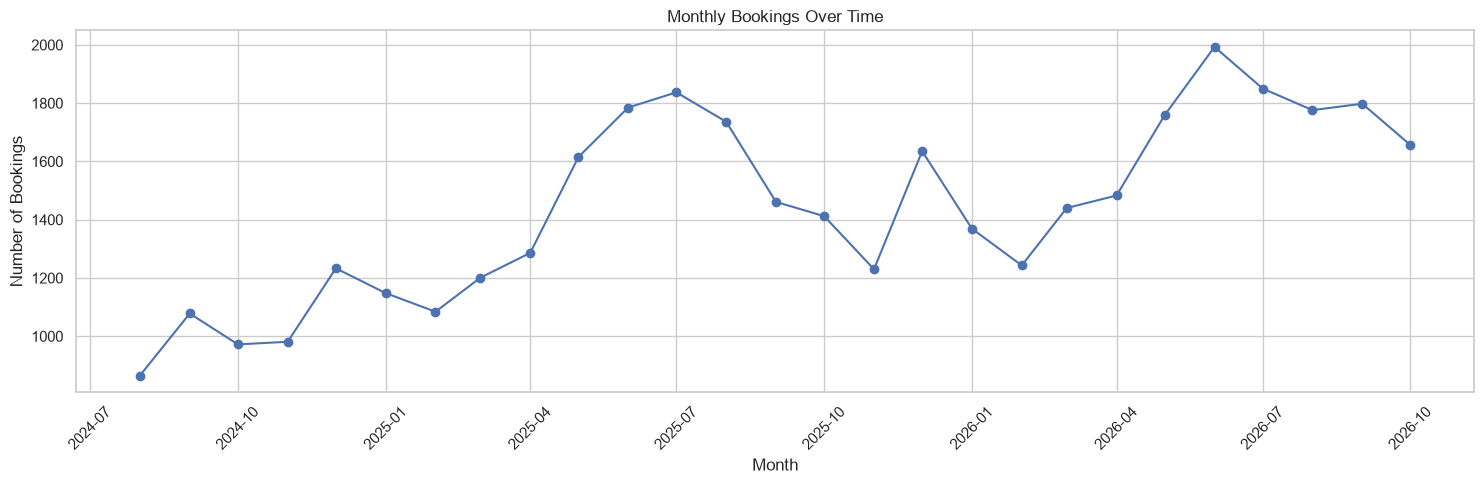

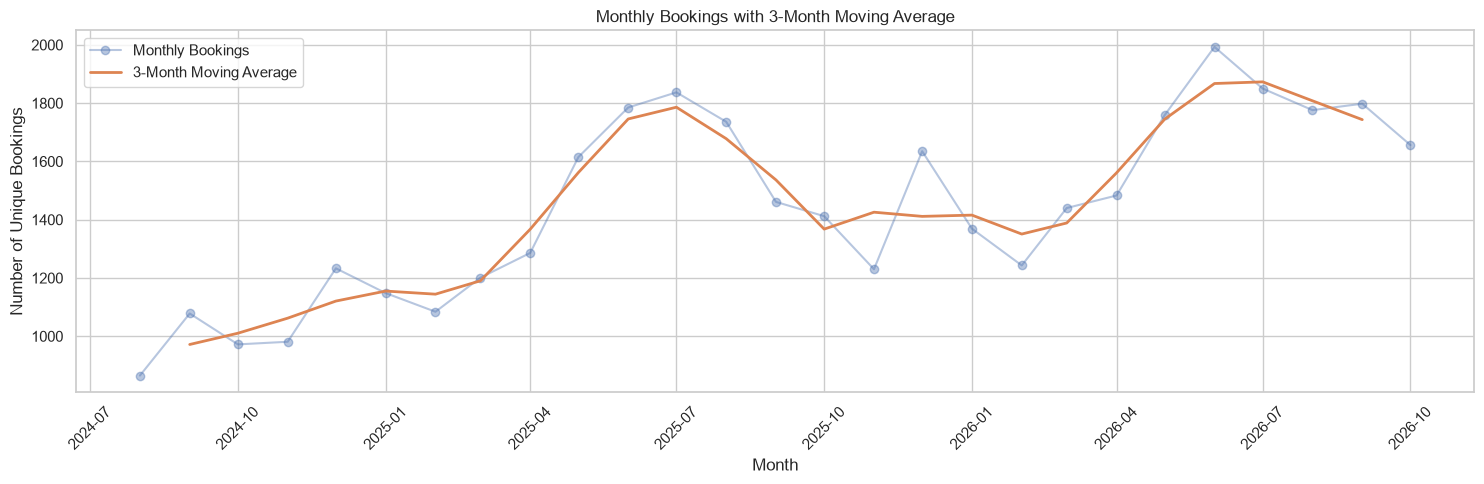

In [76]:
booking_time = (
    df.groupby(pd.Grouper(key="date_parsed", freq="MS"))["number"]
    .nunique())
plt.figure(figsize=(15, 5))

plt.plot(booking_time.index, booking_time.values, marker="o")

plt.title("Monthly Bookings Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
booking_rolling = booking_time.rolling(window=3,center=True).mean()

plt.figure(figsize=(15, 5))

plt.plot(booking_time.index, booking_time.values,
         alpha=0.4, marker="o", label="Monthly Bookings")

plt.plot(booking_rolling.index, booking_rolling.values,
         linewidth=2, label="3-Month Moving Average")

plt.title("Monthly Bookings with 3-Month Moving Average")
plt.xlabel("Month")
plt.ylabel("Number of Unique Bookings")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

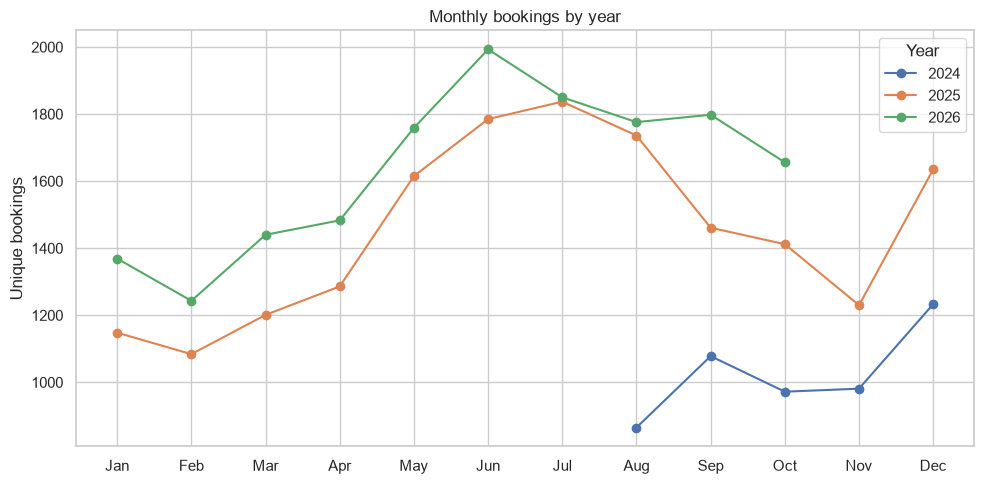

In [82]:
booking_year = (booking_time
           .to_frame("bookings")
           .assign(year=lambda d: d.index.year, month=lambda d: d.index.month)
           .pivot(index="month", columns="year", values="bookings"))

ax = booking_year.plot(figsize=(10, 5), marker="o")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set(title="Monthly bookings by year", xlabel="", ylabel="Unique bookings")
ax.legend(title="Year")
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

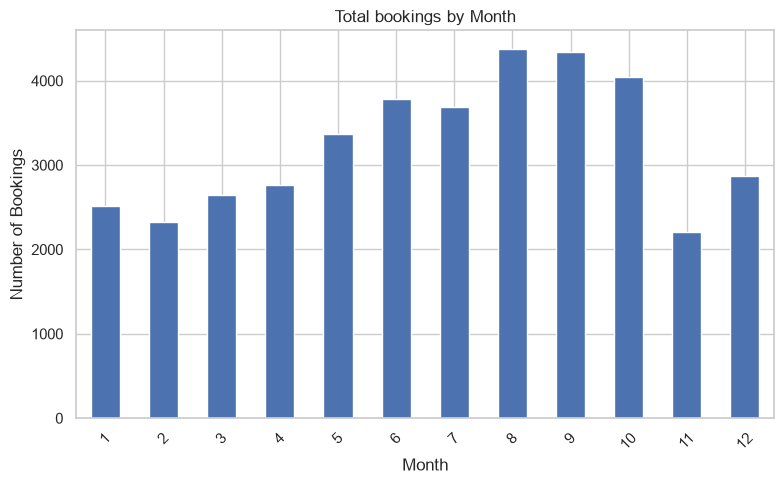

In [ ]:
booking_month= df.groupby("month")["number"].nunique()

booking_month.plot(kind="bar", figsize=(8,5))
plt.title("Total bookings by Month")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show


<function matplotlib.pyplot.show(close=None, block=None)>

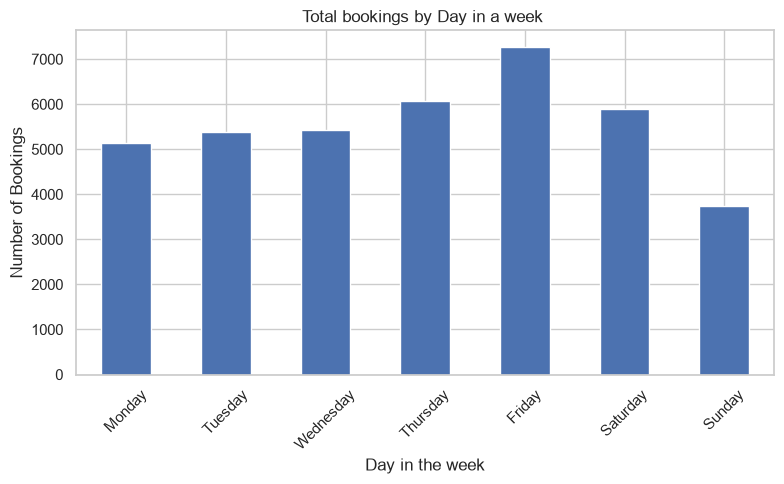

In [43]:
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
booking_day = df.groupby("day_of_week")["number"].nunique()
booking_day = booking_day.reindex(day_order)
booking_day.plot(kind="bar", figsize = (8,5))
plt.title("Total bookings by Day in a week ")
plt.xlabel("Day in the week")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show

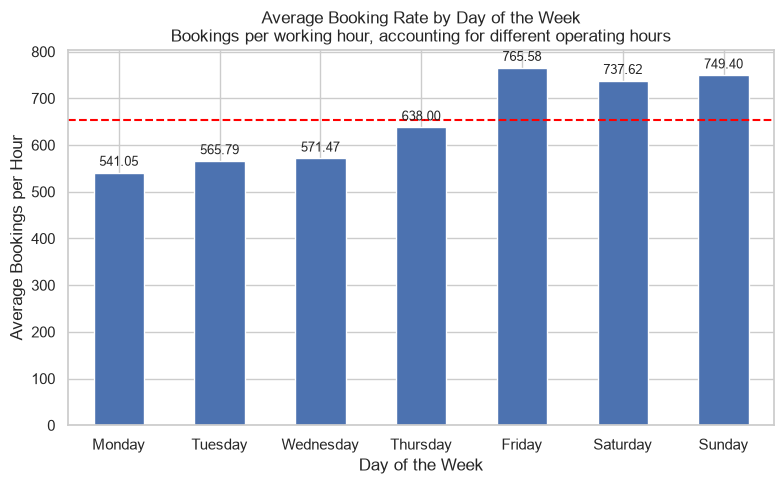

In [62]:
daily_hours = {
    "Monday": 9.5, "Tuesday": 9.5, "Wednesday": 9.5, "Thursday": 9.5, "Friday": 9.5, "Saturday": 8, "Sunday": 5
}
daily_rate = booking_day/booking_day.index.get_level_values("day_of_week").map(daily_hours)
avg_day_rate = daily_rate.groupby("day_of_week").mean()
avg_day_rate = avg_day_rate.reindex(day_order)
ax = avg_day_rate.plot(kind="bar", figsize=(8, 5))

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize = 9)
ax.set_title(
    "Average Booking Rate by Day of the Week\n"
    "Bookings per working hour, accounting for different operating hours",
    fontsize=12
)
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Average Bookings per Hour")
ax.axhline(
    y=avg_day_rate.mean(),
    color="red",
    linestyle='--',
    linewidth=1.5,
    label='Weekly Average'
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



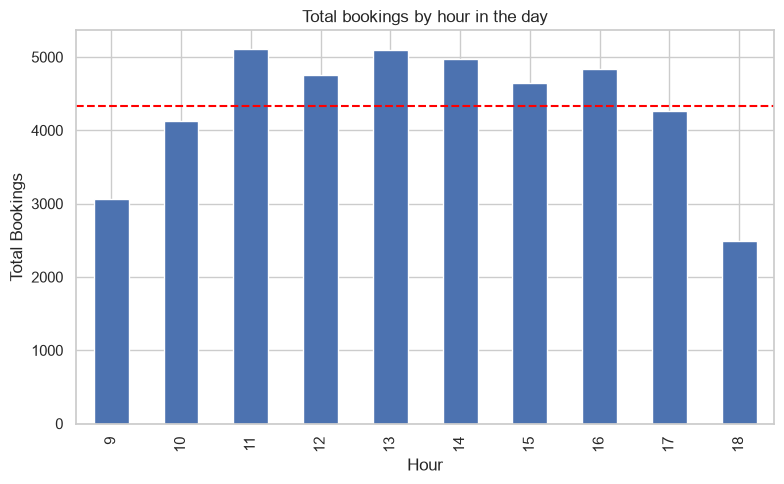

In [ ]:
# Bookings per hour
booking_hour = df[(df["hour"]>=9) & (df["hour"]<=18)].groupby("hour")["number"].nunique()
ax = booking_hour.plot(kind="bar", figsize = (8,5))
ax.set_title("Total bookings by hour in the day")
ax.set_xlabel("Hour")
ax.set_ylabel("Total Bookings")
ax.axhline(
    y = booking_hour.mean(),
    color='red',
    linestyle="--"
)
plt.tight_layout() 
plt.show()

**Summary**:
- Overall, it can be seen that Pedi N Nails is a increasing business with increasing number of appointments made throughout the 3-year period. However, it is also a highly seasonal business, with business always has the peak around the summer months (June-July), another peak in December